## Plot 2D slices of the gamma ray, synchrotron, and number densities

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable

from transform_data import get_transformed_data

import flash_amr_tools
import h5py

In [4]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

# load the bowshock config
bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [20]:
sims = ["ISM-v30", "ISM-v30-MDiff", "ISM-v30-HDiff", "ISM-v100"]
fields = ["gamma"]

times = [30, 60, 90, 120]

sim_textlabel = {
    "ISM-v30" : (10, -22),
    "ISM-v30-MDiff" : (10, -22),
    "ISM-v30-HDiff" : (10, -22),
    "ISM-v100" : (8, -22)
}

field_labels = {
    "ncr" : r"$n_\mathrm{CR, p}$ / cm$^{-3}$",
    "gamma" : r"Gamma-ray Emissivity $j_\gamma$ / erg s$^{-1}$ cm$^{-3}$",
    "ncre" : r"$\epsilon_\mathrm{CR, e}$ / erg cm$^{-3}$",
    "synch" : r"Synchrotron Emissivity $j_\mathrm{syn, 1.4GHz}$ / erg s$^{-1}$ cm$^{-3}$"
}

field_cmaps = {
    "ncr" : cm.BuGn_r,
    "ncre" : cm.plasma,
    "gamma" : cm.RdPu_r,
    "synch" : cm.cividis
}

field_lims = {
    "ncr" : [1e-15, 1e-7],
    "ncre" : [1e-18, 1e-12],
    "gamma" : [1e-30, 1e-26],
    "synch" : [1e-35, 1e-29]
}

Processing time 30 kyr
Processing simulation ISM-v30
<KeysViewHDF5 ['t120_bbox', 't120kyr', 't150_bbox', 't150kyr', 't30_bbox', 't30kyr', 't60_bbox', 't60kyr', 't90_bbox', 't90kyr']>
1.6074408938590427e-35 2.7181158505848976e-27
Processing simulation ISM-v30-MDiff
<KeysViewHDF5 ['t120_bbox', 't120kyr', 't150_bbox', 't150kyr', 't30_bbox', 't30kyr', 't60_bbox', 't60kyr', 't90_bbox', 't90kyr']>
1.8703558899409115e-35 7.471029803213223e-28
Processing simulation ISM-v30-HDiff
<KeysViewHDF5 ['t120_bbox', 't120kyr', 't150_bbox', 't150kyr', 't30_bbox', 't30kyr', 't60_bbox', 't60kyr', 't90_bbox', 't90kyr']>
4.511093173668112e-34 2.3419810419901844e-28
Processing simulation ISM-v100
<KeysViewHDF5 ['t120_bbox', 't120kyr', 't30_bbox', 't30kyr', 't60_bbox', 't60kyr', 't90_bbox', 't90kyr']>
2.1562566073006765e-35 6.054765844488373e-28
Processing time 60 kyr
Processing simulation ISM-v30
<KeysViewHDF5 ['t120_bbox', 't120kyr', 't150_bbox', 't150kyr', 't30_bbox', 't30kyr', 't60_bbox', 't60kyr', 't90_bb

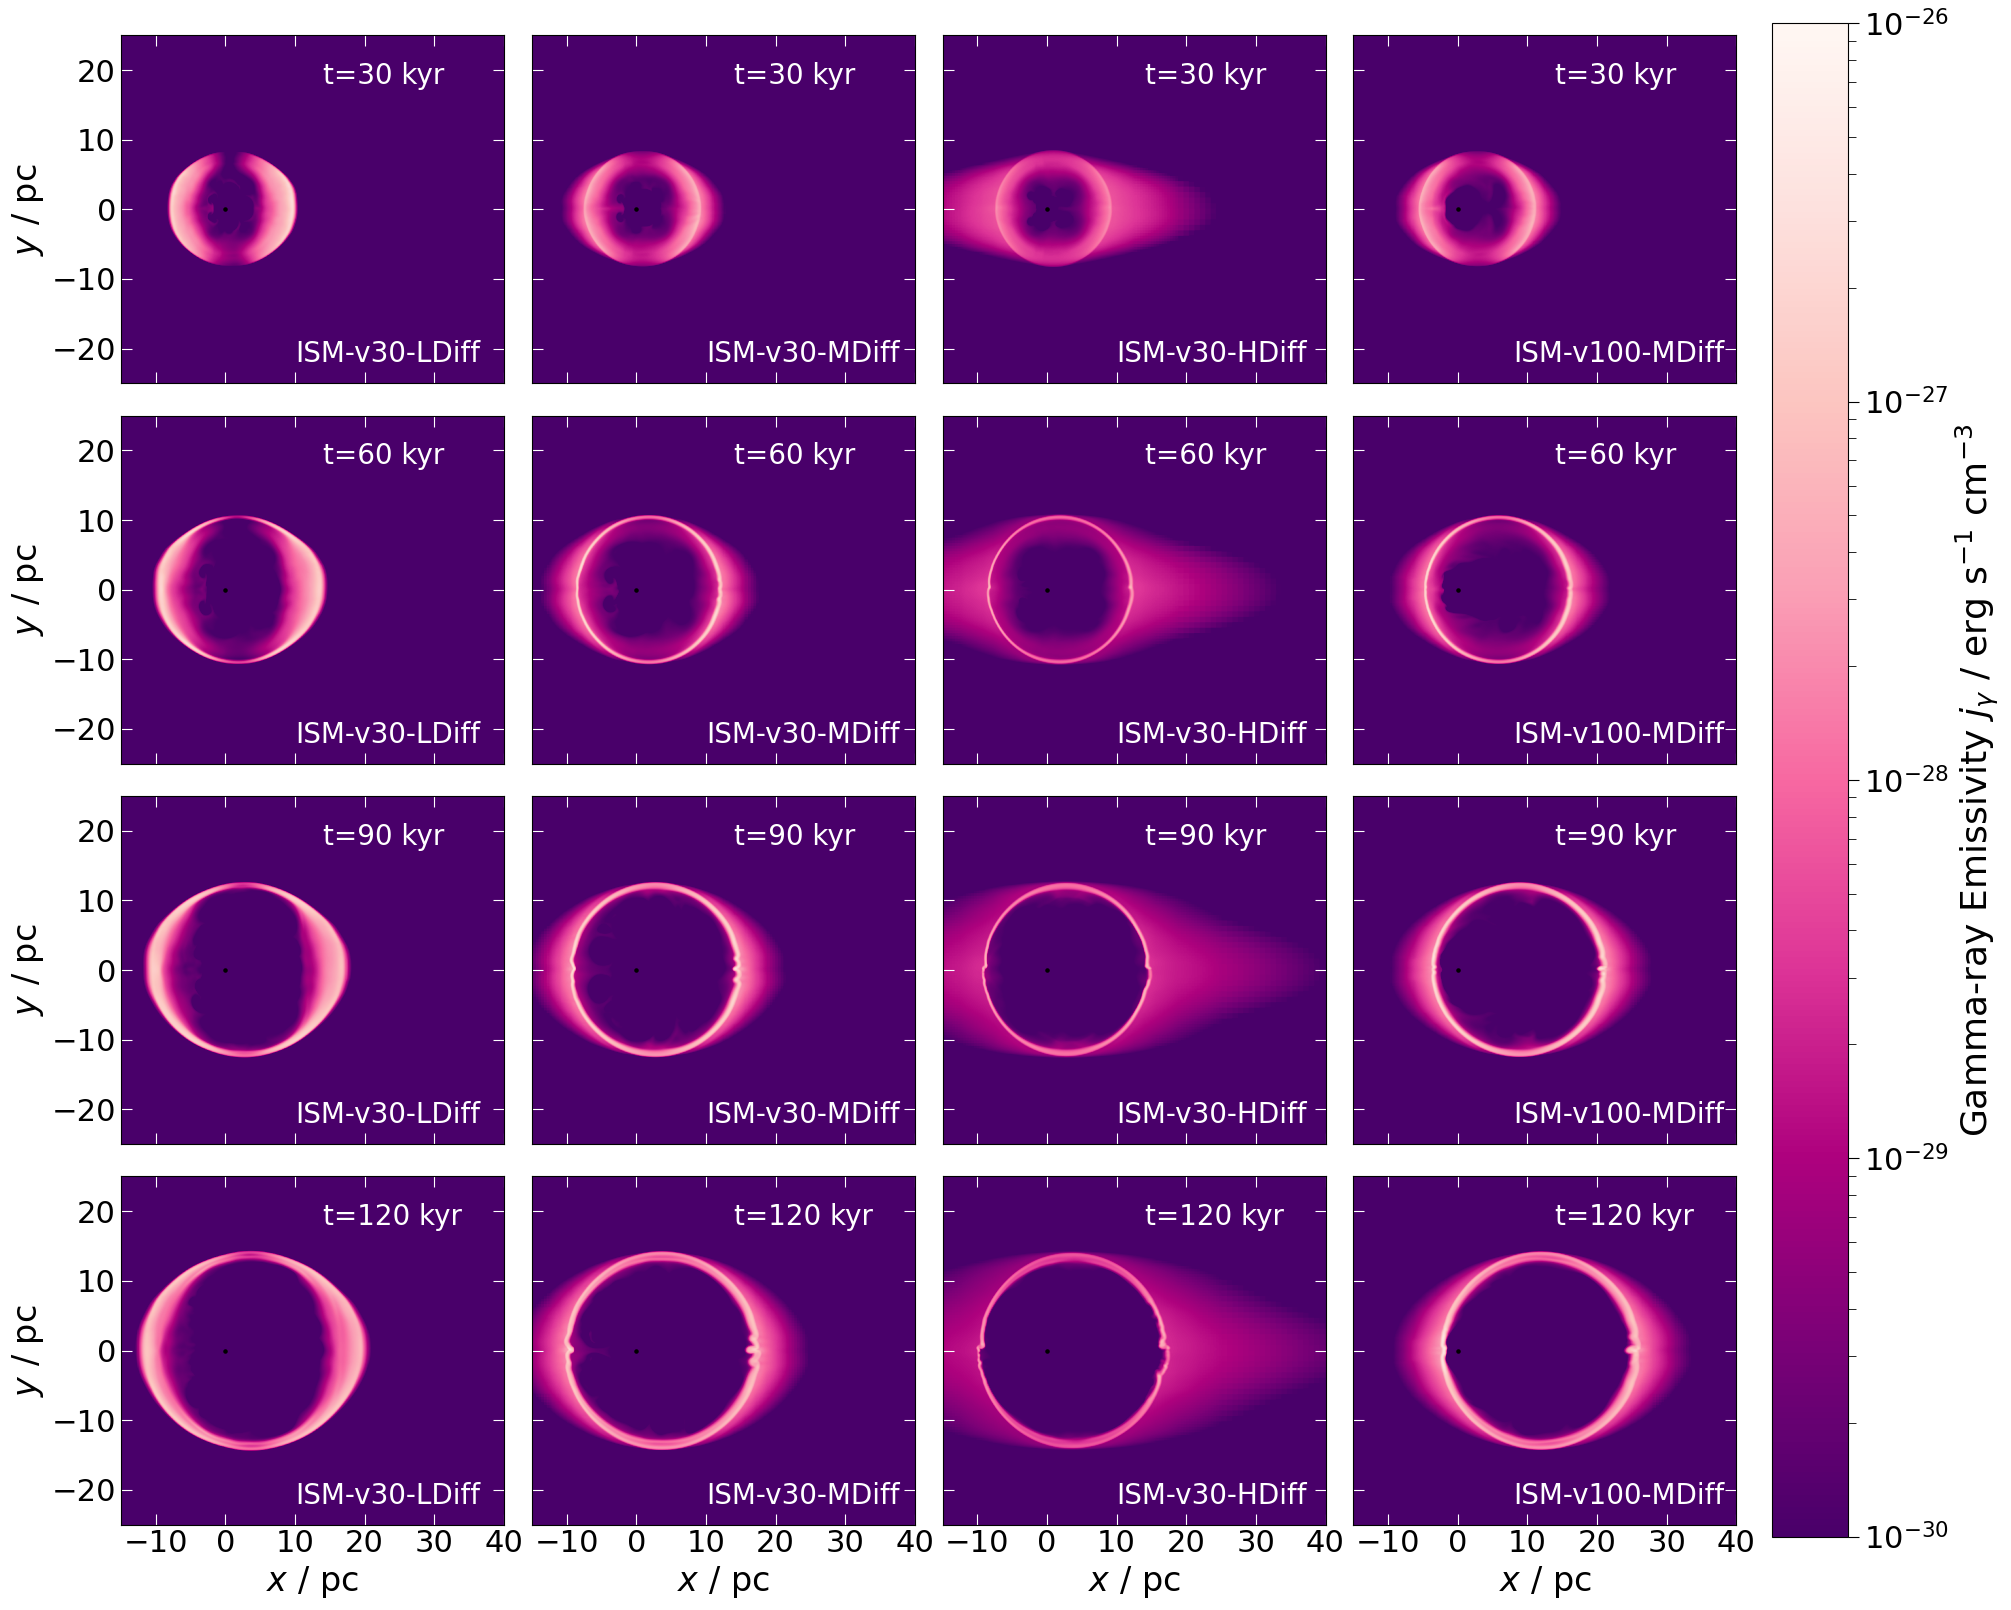

In [25]:
for ifield, field in enumerate(fields):

    fig = plt.figure(figsize=(20,16), constrained_layout=True)
    gs = fig.add_gridspec(len(times), len(sims), hspace=0, wspace=0)
    axs = gs.subplots(sharex=True, sharey=True)

    for itime, time in enumerate(times):
        print(f"Processing time {time} kyr")
        for isim, sim in enumerate(sims):
            print(f"Processing simulation {sim}")
            # f_label = "ncr" if field.find("ncre") != -1 else field
            # f_label = "synch_alpha42" if field.find("synch") != -1 else field
            f_label = field

            # write data to h5py file
            with h5py.File(f"{data_dir}/emission_data_{f_label}_timecorrected.h5", "r") as pf:
                if field == "ncr":
                    
                    field_slice = pf[f"{sim}/proton/slices/t{time}kyr"][()]
                    bbox =  pf[f"{sim}/proton/slices/t{time}kyr_bbox"][()]
                elif field == "ncre":
                    print(pf[f"{sim}/electron/slices"].keys())
                    field_slice = pf[f"{sim}/electron/slices/t{time}kyr"][()]
                    bbox =  pf[f"{sim}/electron/slices/t{time}kyr_bbox"][()]
                else:
                    print(pf[f"{sim}/slices"].keys())
                    field_slice = pf[f"{sim}/slices/t{time}kyr"][()]
                    bbox =  pf[f"{sim}/slices/t{time}_bbox"][()]
            
            print(field_slice.min(), field_slice.max())

            low_cor, up_cor = bbox[0,:,0], bbox[-1,:,1]
            # extent for imshow
            extent = ([low_cor[0], up_cor[0], low_cor[1], up_cor[1]] * u.cm).to_value(u.pc)

            # normaliztion for color
            norm = mcolors.LogNorm(vmin=field_lims[field][0], vmax=field_lims[field][1], clip=True)

            im = axs[itime, isim].imshow(field_slice.T, norm=norm, cmap=field_cmaps[field], origin="lower", extent=extent)
            axs[itime, isim].scatter(0, 0, s=5.0, color="k")

            # limits
            axs[itime, isim].set_xlim(-15,40)
            axs[itime, isim].set_ylim(-25,25)

            # add annotations for the simulation labels
            axs[itime, isim].annotate(f"t={time} kyr", xy=(14, 18), color="w", fontsize=20, zorder=100)
            axs[itime, isim].annotate(bowshock_config[sim]["label"], xy=sim_textlabel[sim], color="w", fontsize=20, zorder=100)

            # labels
            if itime == len(times) -1:
                axs[itime, isim].set_xlabel("$x$ / pc", fontsize=24)
            if isim == 0 :
                axs[itime, isim].set_ylabel("$y$ / pc", fontsize=24)

            if itime == len(times) -1:
                # ticks
                axs[itime, isim].tick_params(axis='x', direction="in", which='major', size=8, labelsize=22, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=20, top=True, right=True, color="w")
            else:
                axs[itime, isim].tick_params(axis='x', direction="in", which='major', size=8, labelsize=0, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=0, top=True, right=True, color="w")
            if isim == 0:
                axs[itime, isim].tick_params(axis='y', direction="in", which='major', size=8, labelsize=22, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=20, top=True, right=True, color="w")
            else:
                # ticks
                axs[itime, isim].tick_params(axis='y', direction="in", which='major', size=8, labelsize=0, top=True, right=True, color="w")
                axs[itime, isim].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=0, top=True, right=True, color="w")
    
    cb = fig.colorbar(im, ax=axs.ravel().tolist(), orientation="vertical", pad=0.01, fraction=0.1)
    cb.ax.set_ylabel(field_labels[field], fontsize=26)
    cb.ax.tick_params(axis='both', which='major', size=8, labelsize=22)
    cb.ax.tick_params(axis='both', which='minor', size=6, labelsize=22)
    cb.ax.set_yscale("log")

    fig.savefig(f"{fig_dir}/2d_slices_{field}_timeevo.png", dpi=250, bbox_inches="tight")
    # fig.savefig(f"{fig_dir}/{field}/2d_slices_t200.png", dpi=200, bbox_inches="tight")